# Quantum agents in the Gym: deep Q-learning with a quantum circuit — a reproduction

**Paper:** Skolik, Jerbi, Dunjko, *Quantum agents in the Gym: a variational quantum algorithm for deep Q-learning*, Quantum 6, 720 (2022), [arXiv:2103.15084](https://arxiv.org/abs/2103.15084).

This notebook presents the reproduction as a scientific argument: the claim, the evidence, the alternative explanations we tested, and an exact statement of what did and did not reproduce. It is meant as the entry point for students and researchers.

**How to read it**

- Cells marked **live** run here on a CPU. The whole notebook takes about 5 minutes.
- Cells marked **stored** load results from `results/` (durable summaries of the full runs: 10 agents per setting, up to 5000 episodes each, produced on a remote L4 GPU and a laptop CPU as documented in `LOG.md`). The source of every stored number is named in its cell.
- After each major result four labelled lines follow: **Observation** (what is visible), **Inference** (what explanation it supports), **Remaining uncertainty**, **Claim impact** (reproduced, weakened, contradicted, unresolved).

**Contents** 1 Claim · 2 Data, metrics, protocol · 3 Mathematics · 4 Known-answer checks · 5 Model walkthrough · 6 Live experiments · 7 Headline result · 8 Fair baselines · 9 Controls and ablations · 10 Robustness and uncertainty · 11 Photonic (MerLin) adaptation · 12 Limitations and conclusion.

## 1. Problem statement and the paper's claims

**Reinforcement learning (RL) in one paragraph.** An agent acts in an environment, receives rewards, and learns a *Q-function* $Q(s,a)$: the expected discounted return of taking action $a$ in state $s$ and acting well afterwards. *Deep Q-learning* (DQN) fits $Q$ with a function approximator, using stored past transitions (experience replay) and a slowly updated copy of the approximator (target network). The paper replaces the usual neural network (NN) by a **parametrized quantum circuit (PQC)** on 4 qubits.

**Claims we test** (numbering follows `LOG.md`):

| ID | Claim in the paper | Where in the paper |
|---|---|---|
| C1 | A PQC with basis-state encoding solves deterministic Frozen Lake; deeper circuits (5, 10, 15 layers) converge faster and get closer to the optimal Q-values | Fig. 3 |
| C2 | The circuit's output range must match the range of optimal Q-values; trainable output weights beat fixed ranges [0,1], [0,90], [0,180] | Fig. 5 |
| C3 | On Cart Pole, data re-uploading and trainable input scaling are both needed | Fig. 4 |
| C4 | A value-based PQC agent solves Cart Pole v0 to its official specification | Figs. 4-7 |
| C5 | More parameters help only up to a point, for PQCs and for NNs; the best NN solves about twice as fast as the best PQC | Fig. 6 |
| C6 | The best individual PQC and NN agents are close (206 vs 186 episodes) | Fig. 7 |

**Falsifiable question.** *With the authors' own settings and 10 independently seeded agents per setting, do the reported outcomes (solves / fails, ordering, episodes to solve) reappear, and does the PQC-versus-NN statement survive a comparison at matched parameter count and equal tuning?*

**Evidence that would weaken a claim.** A setting the paper says fails that solves (or the reverse); an episodes-to-solve value outside our 95% interval; a reversed ordering; a PQC-versus-NN difference that flips sign when the baseline is matched and tuned.

**Kinds of evidence, kept apart:** *reproduction* (the paper's own settings), *controls* (single-change variants that test explanations, section 9), *robustness* (seeds, tuning, hardware, section 10), *extension* (a MerLin photonic adaptation, section 11, which is **not** part of the reproduction).

## 2. Data, metrics, protocol

**No static dataset.** All experience comes online from two simulators (Gymnasium 1.4.0; the authors used gym 0.17.2, whose dynamics we checked equal by reading the sources):

- **Cart Pole v0**: balance a pole on a cart; observation of 4 numbers; reward 1 per step; an episode ends after 200 steps or when the pole falls, so the score is at most 200. *Solved* = mean score of the last 100 episodes at least 195.
- **Frozen Lake 4x4 (deterministic)**: walk from start to goal on a grid with holes; 16 states, 4 actions; reward 1 only at the goal. *Solved* = 100 consecutive episodes reaching the goal. Episodes end after 100 steps, as in the authors' runs (the paper text says 200).

**Metric.** *Episodes to solve*: the 0-based index of the episode at which an agent meets the rule. Agents that never solve within the 5000-episode cap are **censored at 5000**; we always report the solved count next to means. For Frozen Lake we also track the mean absolute error (MAE) to the analytic optimal Q-values over the 44 state-action pairs of non-terminal states (the only definition that reproduces the paper's starting value 0.54, section 4).

**Protocol.** 10 agents (seeds 0-9) per setting, trained together but independently (each has its own parameters, replay memory and random numbers). Selection of hyperparameters (only for the added baselines, section 8) uses separate seeds 100-104. We report **two complete run sets**:

| Run set | Meaning |
|---|---|
| `paper-table` | hyperparameters exactly as in the paper's Appendix B tables |
| `code-faithful` | as above, except two settings where the authors' released code differs from the tables: Cart Pole replay memory unbounded (table: 10000) and Frozen Lake model update every step (table: every 5 steps) |

The code-faithful set is the one compared with the paper's figures (section 9 shows why).

In [1]:
import json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import stats
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")

# Locate the paper folder (the notebook lives in it) and make `lib/` importable.
for candidate in [Path.cwd(), *Path.cwd().parents, Path.cwd() / "papers" / "quantum_agents_deep_q_learning"]:
    if (candidate / "lib" / "dqn.py").exists() and (candidate / "results").exists():
        PROJECT = candidate
        break
else:
    raise FileNotFoundError("Run the notebook from papers/quantum_agents_deep_q_learning")
sys.path.insert(0, str(PROJECT))
sys.path.insert(0, str(PROJECT.parents[1]))
sys.path.insert(0, str(PROJECT / "utils"))

# Reusable implementation code lives in lib/ (this notebook only calls into it).
from lib.dqn import DQNTrainer
from lib.models import PQCQFunction, build_q_function
from lib.optim import MaskedAdam
from lib.qfunction_merlin import MerlinQFunction
from lib.reference import optimal_q_values, terminal_states

import gymnasium, merlin, perceval
gymnasium.logger.min_level = gymnasium.logger.ERROR   # silence the CartPole-v0 deprecation notice
import diagnose_frozenlake_qstar_fit as dfq   # supervised Q* fit used in sections 9 and 11

RES = PROJECT / "results"
CAP = 5000
DEVICE = torch.device("cpu")
torch.set_num_threads(4)

def load_config(name):
    return json.loads((PROJECT / "configs" / f"{name}.json").read_text())

def censored(values):
    return np.array([CAP if v is None else v for v in values], dtype=float)

stats_pt = json.loads((RES / "statistics.json").read_text())["configs"]            # paper-table set
stats_cf = json.loads((RES / "statistics_codefaithful.json").read_text())["configs"]  # code-faithful set
phase5 = json.loads((RES / "phase5_comparison.json").read_text())
merlin_cmp = json.loads((RES / "merlin_comparison.json").read_text())["pairs"]
reference = json.loads((RES / "notebook_reference.json").read_text())
solved_at = reference["solved_at"]

print(f"torch {torch.__version__} | gymnasium {gymnasium.__version__} | merlin {merlin.__version__} "
      f"(pip: merlinquantum 0.4.2) | perceval {perceval.__version__}")
print(f"live device: {DEVICE} | CPU threads: {torch.get_num_threads()} | cuda available: {torch.cuda.is_available()}")
print(f"stored runs: {len(stats_pt)} paper-table + {len(stats_cf)} code-faithful configurations, "
      f"{len(solved_at)} per-agent records, 10 agents each")

torch 2.4.1 | gymnasium 1.4.0 | merlin 0.4.1 (pip: merlinquantum 0.4.2) | perceval 1.3.1
live device: cpu | CPU threads: 4 | cuda available: False
stored runs: 35 paper-table + 29 code-faithful configurations, 52 per-agent records, 10 agents each


## 3. Minimum mathematics

**DQN.** The agent stores transitions $(s,a,r,s')$. At each update it samples a batch and minimises
$$\mathcal L=\frac1B\sum_{i}\big(Q_\theta(s_i,a_i)-y_i\big)^2,\qquad y_i=r_i+\gamma\,(1-d_i)\max_{a'}Q_{\theta^-}(s'_i,a'),$$
where $\theta^-$ are the target-network parameters (copied from $\theta$ every few steps), $d_i=1$ if the transition ended the episode, $\gamma$ is the discount (0.99 Cart Pole, 0.8 Frozen Lake), and actions are chosen $\varepsilon$-greedily with $\varepsilon$ decaying from 1 to 0.01 by a factor 0.99 per episode.

**The quantum Q-function (paper Fig. 1).** $L$ layers; layer $l$ applies an optional encoding $\bigotimes_i R_X\big(\arctan(x_i w^{(l)}_i)\big)$, then $R_Y(\theta)R_Z(\theta')$ on every qubit, then CZ gates on the ring $(0,1),(1,2),(2,3),(3,0)$. With data re-uploading the encoding repeats in every layer (per-layer trainable scales $w^{(l)}$); the Cart Pole readout is
$$Q(s,a)=\frac{\langle O_a\rangle+1}{2}\,w_{o,a},\qquad O_{\text{left}}=Z_0Z_1,\ O_{\text{right}}=Z_2Z_3 .$$
The factor $(\langle O\rangle+1)/2\in[0,1]$ is why the **output weights** $w_o$ matter: optimal Cart Pole Q-values reach about 86, so a bounded output must be rescaled (claim C2). Frozen Lake encodes the state index as a 4-bit basis state and reads $Z_i$ per action; its optimal values never exceed 1, so no rescaling is needed.

**Parameter count (5 layers, Cart Pole):** $5\cdot 8$ angles $+\,5\cdot4$ input scales $+\,2$ output weights $=62$.

**Photonic adaptation (section 11).** Qubit gates are replaced by interferometers on 6 modes with 3 photons; $Q(s,a)$ is the **click probability** of a threshold detector on a readout mode (again in $[0,1]$), times $w_o$.

## 4. Known-answer sanity checks (live)

Before trusting any learning curve we check the building blocks against answers known independently.

In [2]:
# 4a. The PyTorch circuit simulator equals an independent gate-by-gate NumPy simulation (5-layer Cart Pole PQC).
def np_gate_on_qubit(gate, qubit, n):
    operator = np.array([[1.0 + 0j]])
    for index in range(n):
        operator = np.kron(operator, gate if index == qubit else np.eye(2))
    return operator
rx = lambda t: np.array([[np.cos(t/2), -1j*np.sin(t/2)], [-1j*np.sin(t/2), np.cos(t/2)]])
ry = lambda t: np.array([[np.cos(t/2), -np.sin(t/2)], [np.sin(t/2), np.cos(t/2)]])
rz = lambda t: np.array([[np.exp(-0.5j*t), 0], [0, np.exp(0.5j*t)]])
def np_cz(a, b, n):
    d = np.ones(2**n)
    for i in range(2**n):
        bits = [(i >> (n-1-q)) & 1 for q in range(n)]
        if bits[a] and bits[b]: d[i] = -1
    return np.diag(d)
def np_zz(qubits, n):
    op = np.eye(1)
    for i in range(n): op = np.kron(op, np.diag([1, -1]) if i in qubits else np.eye(2))
    return op
def numpy_q(theta, w_in, w_out, x):
    n, state = 4, np.zeros(16, complex); state[0] = 1
    for layer in range(theta.shape[0]):
        for q in range(n):
            state = np_gate_on_qubit(rx(np.arctan(x[q]*w_in[layer, q])), q, n) @ state
        for q in range(n):
            state = np_gate_on_qubit(ry(theta[layer, q, 0]), q, n) @ state
            state = np_gate_on_qubit(rz(theta[layer, q, 1]), q, n) @ state
        for q in range(n): state = np_cz(q, (q+1) % n, n) @ state
    return np.array([(np.real(state.conj() @ np_zz(p, n) @ state) + 1)/2*w_out[a] for a, p in enumerate(((0, 1), (2, 3)))])

cfg = load_config("e2e3_cartpole_optimal_full_codefaithful")
model = PQCQFunction(cfg, [3, 11], n_actions=2, real_dtype=torch.float64)
with torch.no_grad():
    model.input_weights.uniform_(0.5, 1.5); model.output_weights.uniform_(1.0, 50.0)
obs = torch.randn(2, 4, 4, dtype=torch.float64, generator=torch.Generator().manual_seed(0))
torch_q = model(obs).detach().numpy()
worst = max(np.abs(torch_q[a, s] - numpy_q(model.theta[a].detach().numpy(), model.input_weights[a].detach().numpy(),
            model.output_weights[a].detach().numpy(), obs[a, s].numpy())).max() for a in range(2) for s in range(4))
print(f"4a  max |PyTorch - NumPy gate-by-gate| over 8 evaluations: {worst:.2e}")
assert worst < 1e-10

# 4b. Parameter counts equal the paper's (Fig. 6 labels) and our added matched baselines.
rows = []
for label, name, n_actions in [("PQC 5 layers (paper: 62)", "e2e3_cartpole_optimal_full_codefaithful", 2),
                               ("PQC 25 layers (paper: 302)", "e4_cartpole_pqc_l25_codefaithful", 2),
                               ("NN (10,10) (paper: 182)", "e4_cartpole_mlp_10_10_codefaithful", 2),
                               ("NN (20,20) (paper: 562)", "e4_cartpole_mlp_20_20_codefaithful", 2),
                               ("NN (5,5), added match", "e4_cartpole_mlp_5_5_codefaithful", 2),
                               ("NN (14,14), added match", "e4_cartpole_mlp_14_14_codefaithful", 2)]:
    rows.append((label, build_q_function(load_config(name), [0], n_actions, torch.float32).count_trainable_parameters()))
display(pd.DataFrame(rows, columns=["model", "trainable parameters"]))
assert dict(rows)["PQC 5 layers (paper: 62)"] == 62 and dict(rows)["PQC 25 layers (paper: 302)"] == 302

# 4c. Frozen Lake optimal Q-values: only the last step is rewarded, so Q*(14, right) = 1 and Q*(0, down) = gamma^5.
qstar = optimal_q_values(0.8)
RIGHT, DOWN = 2, 1
print(f"4c  Q*(14,right) = {qstar[14, RIGHT]:.4f} (expected 1);  Q*(0,down) = {qstar[0, DOWN]:.4f} (expected 0.8^5 = {0.8**5:.4f})")
assert abs(qstar[14, RIGHT] - 1) < 1e-9 and abs(qstar[0, DOWN] - 0.8**5) < 1e-9

# 4d. Initial error to Q*: the Frozen Lake code initialisation reproduces the paper's starting MAE 0.54 over the 44 non-terminal pairs.
fl = PQCQFunction(load_config("e1_frozenlake_l5_original"), list(range(40)), 4, torch.float64)
q0 = fl(torch.arange(16, dtype=torch.float64).view(1, 16, 1).expand(40, 16, 1))
err = (q0 - torch.tensor(qstar)).abs()
alive = [s for s in range(16) if s not in terminal_states()]
print(f"4d  initial MAE over 44 non-terminal pairs: {float(err[:, alive].mean()):.3f}  (paper Fig. 3b starts at ~0.54);"
      f" over all 64 pairs: {float(err.mean()):.3f}")
assert abs(float(err[:, alive].mean()) - 0.54) < 0.02

4a  max |PyTorch - NumPy gate-by-gate| over 8 evaluations: 7.11e-15


,model,trainable parameters
0,PQC 5 layers (paper: 62),62
1,PQC 25 layers (paper: 302),302
2,"NN (10,10) (paper: 182)",182
3,"NN (20,20) (paper: 562)",562
4,"NN (5,5), added match",67
5,"NN (14,14), added match",310


4c  Q*(14,right) = 1.0000 (expected 1);  Q*(0,down) = 0.3277 (expected 0.8^5 = 0.3277)
4d  initial MAE over 44 non-terminal pairs: 0.542  (paper Fig. 3b starts at ~0.54); over all 64 pairs: 0.467


In [3]:
# 4e. The masked Adam only moves agents selected by the mask, and agents are independent of their batch mates.
p = torch.nn.Parameter(torch.zeros(2, 3)); optimiser = MaskedAdam([([p], 0.1, False)], 0.9, 0.999, 1e-7)
p.grad = torch.ones(2, 3); optimiser.step(torch.tensor([True, False]))
print("4e  masked Adam step -> agent 0:", p[0].tolist(), "| agent 1 (masked out):", p[1].tolist())
assert torch.all(p[1] == 0) and torch.all(p[0] != 0)

def short_run(seeds, episodes=6):
    c = load_config("e2e3_cartpole_optimal_full_codefaithful"); c["agents"]["seeds"] = seeds; c["training"]["max_episodes"] = episodes
    return DQNTrainer(c, DEVICE, torch.float64).train().scores
alone, together = short_run([5]), short_run([5, 9])
print("    agent seed 5 alone      :", alone[0])
print("    agent seed 5 with seed 9:", together[0])
assert alone[0] == together[0]
print("4e  an agent's whole trajectory is identical alone or in a batch: independence confirmed")

4e  masked Adam step -> agent 0: [-0.09999967366456985, -0.09999967366456985, -0.09999967366456985] | agent 1 (masked out): [0.0, 0.0, 0.0]


    agent seed 5 alone      : [17.0, 20.0, 17.0, 25.0, 27.0, 14.0]
    agent seed 5 with seed 9: [17.0, 20.0, 17.0, 25.0, 27.0, 14.0]
4e  an agent's whole trajectory is identical alone or in a batch: independence confirmed


**Observation.** The simulator matches an independent NumPy implementation to rounding error; parameter counts equal the paper's (62, 302, 182, 562); the analytic Frozen Lake values behave as derived; the code's Frozen Lake initialisation gives the paper's starting error 0.54 over 44 pairs (and a different value over 64); the optimiser and the batched training do not mix agents. **Inference.** The building blocks are correct, so differences from the paper later are not explained by simulator bugs. **Remaining uncertainty.** These checks do not validate the training dynamics against the original TensorFlow code, which could not be run. **Claim impact.** None yet; they license the experiments below.

## 5. Model and pipeline walkthrough

The pipeline is: environment → replay memory → batch → Q-function (PQC, NN or photonic) → loss with target network → masked Adam → repeat, with all agents of a configuration stepped in lockstep (`lib/dqn.py`). The Q-function receives a tensor of shape (agents, batch, observation) and returns (agents, batch, actions).

In [4]:
cfg = load_config("e2e3_cartpole_optimal_full_codefaithful")
pqc = build_q_function(cfg, list(range(10)), 2, torch.float32)
print("PQC (5 layers, re-uploading, trainable input and output weights)")
print("  parameters per agent by group:")
for group in pqc.parameter_groups():
    print(f"    {group.name:<14s} learning-rate key '{group.learning_rate_key}', AMSGrad {group.amsgrad}, "
          f"{sum(t[0].numel() for t in group.tensors)} values")
print("  settings:", {k: cfg["model"][k] for k in ("n_layers", "ansatz", "encoding_activation", "data_reuploading", "train_input_weights", "train_output_weights")})
print("  training:", {k: cfg["training"][k] for k in ("gamma", "batch_size", "update_model_every", "update_target_every", "replay_capacity", "max_episodes")},
      "learning rates", cfg["training"]["learning_rates"])
x = torch.tensor([[[0.02, 0.5, -0.04, -0.7]]]).expand(10, 1, 4)
with torch.no_grad():
    q = pqc(x)
print(f"  Q-values of a typical state for 10 untrained agents: min {float(q.min()):.3f}, max {float(q.max()):.3f} "
      "(inside [0, 1]: output weights start at 1; training must stretch them towards ~86)")

nn_cfg = load_config("e5_eval_mlp_14_14_classical")
print("NN (14,14), tuned setting:", {k: nn_cfg["training"][k] for k in ("batch_size", "update_model_every", "update_target_every")},
      "| parameters", build_q_function(nn_cfg, [0], 2, torch.float32).count_trainable_parameters())

PQC (5 layers, re-uploading, trainable input and output weights)
  parameters per agent by group:
    variational    learning-rate key 'main', AMSGrad True, 40 values
    input_weights  learning-rate key 'input_weights', AMSGrad False, 20 values
    output_weights learning-rate key 'output_weights', AMSGrad False, 2 values
  settings: {'n_layers': 5, 'ansatz': 'ry_rz_cz_ring', 'encoding_activation': 'arctan', 'data_reuploading': True, 'train_input_weights': True, 'train_output_weights': True}
  training: {'gamma': 0.99, 'batch_size': 16, 'update_model_every': 1, 'update_target_every': 1, 'replay_capacity': None, 'max_episodes': 5000} learning rates {'main': 0.001, 'input_weights': 0.001, 'output_weights': 0.1}
  Q-values of a typical state for 10 untrained agents: min 0.284, max 0.708 (inside [0, 1]: output weights start at 1; training must stretch them towards ~86)
NN (14,14), tuned setting: {'batch_size': 32, 'update_model_every': 1, 'update_target_every': 1} | parameters 310


## 6. Small live experiments

Three short runs on this CPU. Their purpose is to show the learning dynamics and to test **reproducibility against the stored full runs** (which ran on a remote GPU or this laptop).

- **6a** Cart Pole, 5-layer PQC, 3 agents, 200 episodes (the full runs use 10 agents and up to 5000 episodes). *Reduction:* 3 of 10 agents, 200 episodes.
- **6b** Frozen Lake, 15-layer PQC, 3 agents until solved (full runs: 10 agents).
- **6c** NN (14,14) with the tuned setting, all 10 agents (this one is a complete run).

live run: 92 s on CPU, 24087 lockstep iterations


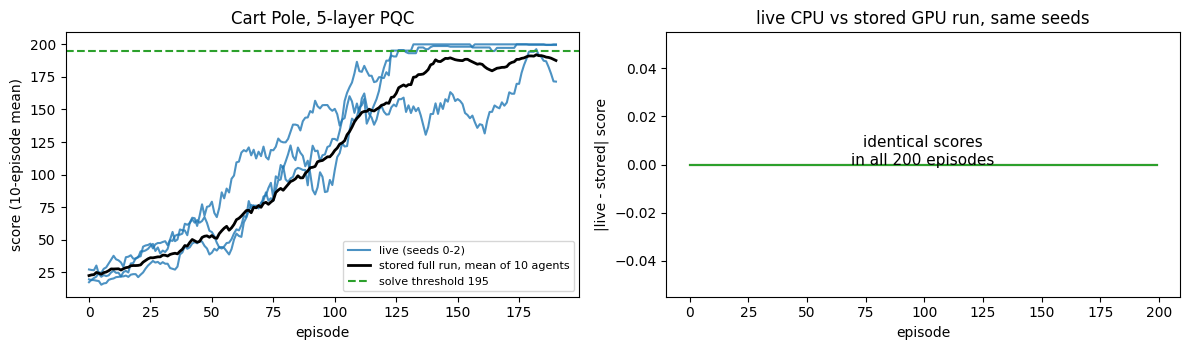

first episode where live differs from the stored GPU run, per seed: [None, None, None]
final-20-episode mean score (live): [199.8, 199.8, 182.8]


In [5]:
# 6a (live, ~1.5 min). Cart Pole PQC 5 layers, seeds 0-2, 200 episodes, code-faithful settings.
cfg = load_config("e2e3_cartpole_optimal_full_codefaithful"); cfg["agents"]["seeds"] = [0, 1, 2]; cfg["training"]["max_episodes"] = 200
start = time.perf_counter()
live_cp = DQNTrainer(cfg, DEVICE, torch.float32).train()
print(f"live run: {time.perf_counter() - start:.0f} s on CPU, {live_cp.lockstep_iterations} lockstep iterations")

stored = np.array(reference["cartpole_full_scores_first300"]["scores"])[:, :200]
live = np.array([s[:200] for s in live_cp.scores])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
smooth = lambda y, k=10: np.convolve(y, np.ones(k)/k, mode="valid")
for i, row in enumerate(live):
    axes[0].plot(smooth(row), color="tab:blue", alpha=.8, label="live (seeds 0-2)" if i == 0 else None)
axes[0].plot(smooth(stored.mean(0)), color="k", lw=2, label="stored full run, mean of 10 agents")
axes[0].axhline(195, color="tab:green", ls="--", label="solve threshold 195")
axes[0].set(xlabel="episode", ylabel="score (10-episode mean)", title="Cart Pole, 5-layer PQC"); axes[0].legend(fontsize=8)
differs = [int(np.flatnonzero(live[a] != stored[a])[0]) if np.any(live[a] != stored[a]) else None for a in range(3)]
axes[1].plot(np.abs(live - stored[:3]).T); axes[1].set(xlabel="episode", ylabel="|live - stored| score", title="live CPU vs stored GPU run, same seeds")
if np.abs(live - stored[:3]).max() == 0:
    axes[1].text(0.5, 0.5, "identical scores\nin all 200 episodes", transform=axes[1].transAxes, ha="center", fontsize=11)
plt.tight_layout(); plt.show()
print("first episode where live differs from the stored GPU run, per seed:", differs)
print("final-20-episode mean score (live):", [round(float(np.mean(r[-20:])), 1) for r in live])

**Observation.** In 200 episodes the agents move from random play (about 20 points) to near-maximal scores (the 200 cap; the third seed dips late, final-20 mean 182.8). In the execution recorded above, all three live trajectories are identical, episode by episode, to the stored trajectories of the same seeds from the remote GPU (first difference `None`, difference curve flat at zero). **Inference.** The learning dynamics are those of a functioning DQN, and for this model and horizon the results are reproducible across the two devices. **Remaining uncertainty.** 3 agents and 200 episodes say nothing about episodes *to solve* (the solve rule needs a 100-episode window at 195 and is met later, section 7); identical trajectories over 200 episodes do not guarantee identical ones over thousands of steps (see 6b). **Claim impact.** C4 is only illustrated here; the evidence is in section 7.

In [6]:
# 6b (live, ~1 min). Frozen Lake PQC 15 layers, seeds 0-2, run until each agent solves; compare with the stored run.
cfg = load_config("e1_frozenlake_l15_codefaithful"); cfg["agents"]["seeds"] = [0, 1, 2]
start = time.perf_counter()
live_fl = DQNTrainer(cfg, DEVICE, torch.float32).train()
print(f"live run: {time.perf_counter() - start:.0f} s on CPU")
stored_fl = stats_cf["e1_frozenlake_l15_original"]["solved_episode_indices"][:3]
print("episodes to solve, seeds 0-2  live CPU:", live_fl.solved_at_episode_index, "| stored remote-GPU run:", stored_fl)
print("stored mean over all 10 agents:", round(stats_cf["e1_frozenlake_l15_original"]["mean_censored"]),
      "| live mean over the 3 agents:", round(float(np.mean(live_fl.solved_at_episode_index))))

mae_live = np.array([np.mean([m[min(step, len(m)-1)] for m in live_fl.q_star_mae["nonterminal_44"]]) for step in reference["frozenlake_l15_mae44_mean"]["steps"]])
table = pd.DataFrame({"time step": reference["frozenlake_l15_mae44_mean"]["steps"], "stored mean MAE (10 agents)": np.round(reference["frozenlake_l15_mae44_mean"]["mean"], 3),
                      "live mean MAE (3 agents)": np.round(mae_live, 3)})
display(table)

live run: 72 s on CPU
episodes to solve, seeds 0-2  live CPU: [765, 801, 630] | stored remote-GPU run: [765, 599, 686]
stored mean over all 10 agents: 749 | live mean over the 3 agents: 732


,time step,stored mean MAE (10 agents),live mean MAE (3 agents)
0,0,0.540,0.540
1,250,0.270,0.272
2,500,0.217,0.223
3,1000,0.196,0.200
4,2000,0.176,0.175
5,3000,0.162,0.159


**Observation.** All three live agents solve Frozen Lake (630, 765, 801 episodes; the stored 10-agent run spans 546-1177 with mean 749, the live mean is 732), and the error to the optimal Q-values follows the stored mean curve within 0.01 at every printed step (0.54, 0.27, 0.22, 0.20, 0.18, 0.16). Per seed, only seed 0 equals the stored GPU run (765 episodes); seeds 1 and 2 differ (801 vs 599, 630 vs 686). **Inference.** Reinforcement-learning trajectories can amplify tiny floating-point differences between devices (a different greedy action changes everything afterwards), so *individual seeds* are not portable across hardware even though the *distribution* is. **Remaining uncertainty.** This is one comparison on 3 seeds; we did not quantify how often seeds diverge across devices or why this setting diverges and Cart Pole (6a) did not. **Claim impact.** Supports C1 qualitatively; reinforces why all claims are made on 10-agent distributions, not single seeds.

In [7]:
# 6c (live, ~1 min). NN (14,14), tuned setting, all 10 agents: a complete run, same device (this CPU) as the stored run.
cfg = load_config("e5_eval_mlp_14_14_classical")
start = time.perf_counter()
live_nn = DQNTrainer(cfg, DEVICE, torch.float32).train()
print(f"live run: {time.perf_counter() - start:.0f} s on CPU (stored run: {solved_at['e5_eval_mlp_14_14_classical']['wall_clock_seconds']:.0f} s)")
stored_nn = solved_at["e5_eval_mlp_14_14_classical"]["solved_at"]
print("episodes to solve, live  :", live_nn.solved_at_episode_index)
print("episodes to solve, stored:", stored_nn)
print("identical:", live_nn.solved_at_episode_index == stored_nn, "| mean (censored at 5000) live:",
      round(float(censored(live_nn.solved_at_episode_index).mean())), "stored:", round(float(censored(stored_nn).mean())))

live run: 53 s on CPU (stored run: 53 s)
episodes to solve, live  : [231, 234, 232, 190, 214, 207, 246, 360, 233, 893]
episodes to solve, stored: [231, 234, 232, 190, 214, 207, 246, 360, 233, 893]
identical: True | mean (censored at 5000) live: 304 stored: 304


**Observation.** On the same device a complete 10-agent run reproduces the stored result exactly. **Inference.** The pipeline is deterministic given seeds and hardware, so the stored numbers are not artefacts of an unrepeatable run. **Remaining uncertainty.** Exact agreement is shown on this CPU for this baseline; the circuit runs were produced on a different device (6a, 6b). **Claim impact.** Strengthens the validity of every stored result used below.

## 7. Headline reproduction result (stored)

The full results below come from `results/statistics*.json` (generated from the run folders; command in `LOG.md`). Each row compares the paper's reported value with ours; "Delta" is reproduced minus paper mean episodes; paper values marked ~ were read from the paper's figures (about ±20 episodes); "within CI" means the paper value lies in our 95% bootstrap interval over 10 agents.

In [8]:
# stored: the paper-vs-reproduced table (generated by utils/build_readme_tables.py from results/statistics*.json)
display(Markdown((RES / "readme_results_table.md").read_text()))

| Paper item | Claim tested | Paper value | Reproduced value (code-faithful) | Delta | Metric agreement | Trend agreement | Claim support | Seeds | Comment (paper-table value) |
|---|---|---|---|---:|---|---|---|---:|---|
| Fig. 3a, FL 5 layers | C1: all agents solve | all 10 solve | 10/10 solved, mean 1323 [857, 1982] | -- | count matches | time falls with depth: yes | supported | 10 (0-9) | paper-table: 9/10 solved, mean 2297 [1447, 3170] |
| Fig. 3a, FL 10 layers | C1: all agents solve | all 10 solve | 10/10 solved, mean 821 [623, 1067] | -- | count matches | time falls with depth: yes | supported | 10 (0-9) | paper-table: 8/10 solved, mean 2355 [1510, 3324] |
| Fig. 3a, FL 15 layers | C1: all agents solve | all 10 solve | 10/10 solved, mean 749 [638, 885] | -- | count matches | time falls with depth: yes | supported | 10 (0-9) | paper-table: 10/10 solved, mean 1462 [1041, 1948] |
| Fig. 3b, FL 5 layers | C1: MAE to Q* (44 non-terminal pairs, step 10000) | ~0.19 | 0.169 (s.e.m. 0.004) | -0.021 | lower than paper | ordering by depth: yes | partially supported | 10 (0-9) | paper-table: 0.197; start value 0.54 matches |
| Fig. 3b, FL 10 layers | C1: MAE to Q* (44 non-terminal pairs, step 10000) | ~0.17 | 0.152 (s.e.m. 0.002) | -0.018 | lower than paper | ordering by depth: yes | partially supported | 10 (0-9) | paper-table: 0.192; start value 0.54 matches |
| Fig. 3b, FL 15 layers | C1: MAE to Q* (44 non-terminal pairs, step 10000) | ~0.155 | 0.137 (s.e.m. 0.004) | -0.018 | lower than paper | ordering by depth: yes | partially supported | 10 (0-9) | paper-table: 0.181; start value 0.54 matches |
| Fig. 4a / 5a, CP full, best hparams | C3/C4: solves Cart Pole | <= 600 (text); ~320 (Fig. 6a) | 10/10 solved, mean 303 [254, 364] | -17 | within CI | yes | supported | 10 (0-9) | paper-table: 10/10 solved, mean 617 [415, 866] |
| Fig. 4a, CP w/o re-uploading, best | C3: re-uploading needed | does not solve (text) | 10/10 solved, mean 394 [308, 523] | -- | not reproduced | no: about as fast as full | not supported | 10 (0-9) | paper-table: 10/10 solved, mean 659 [439, 951]; paper's Fig. 4a curve ~190 |
| Fig. 4a, CP w/o input weights, best | C3: trainable w_d needed | does not solve (text) | 8/10 solved, mean 1420 [450, 2714] | -- | not reproduced (8/10 solve) | yes: slower and less reliable | partially supported | 10 (0-9) | paper-table: 5/10 solved, mean 3199 [1951, 4398] |
| Fig. 4b, CP full, sub-optimal | C3: full model robust to hparams | <= 3000 (text) | 10/10 solved, mean 1901 [1187, 2791] | -- | within text bound | yes | supported | 10 (0-9) | paper-table: 9/10 solved, mean 3106 [2254, 3951] |
| Fig. 4b, CP w/o re-uploading, sub-opt. | C3 | does not solve (text) | 8/10 solved, mean 2961 [2152, 3858] | -- | not reproduced | yes: slower, 8/10 solve | partially supported | 10 (0-9) | paper-table: 5/10 solved, mean 3889 [3099, 4593] |
| Fig. 4b, CP w/o input weights, sub-opt. | C3 | does not solve (text) | 5/10 solved, mean 3472 [2405, 4554] | -- | not reproduced | yes: 5/10 solve | partially supported | 10 (0-9) | paper-table: 1/10 solved, mean 4752 [4258, 5000] |
| Fig. 5a, CP fixed [0,1], best | C2: range must match Q* | never solves | 0/10 solved, mean 5000 [5000, 5000] | -- | matches | yes | supported | 10 (0-9) | paper-table: 0/10 solved, mean 5000 [5000, 5000] |
| Fig. 5a, CP fixed [0,90], best | C2 | solves | 10/10 solved, mean 279 [239, 334] | -- | matches | yes | supported | 10 (0-9) | paper-table: 10/10 solved, mean 401 [290, 540] |
| Fig. 5a, CP fixed [0,180], best | C2 | solves (slower) | 10/10 solved, mean 350 [279, 445] | -- | matches | yes | supported | 10 (0-9) | paper-table: 10/10 solved, mean 843 [568, 1149] |
| Fig. 5b, CP fixed [0,1], sub-opt. | C2 | never solves | 0/10 solved, mean 5000 [5000, 5000] | -- | matches | yes | supported | 10 (0-9) | paper-table: 0/10 solved, mean 5000 [5000, 5000] |
| Fig. 5b, CP fixed [0,90], sub-opt. | C2 | solves (~4500) | 10/10 solved, mean 1649 [1249, 2054] | -- | matches (solves earlier) | yes | supported | 10 (0-9) | paper-table: 8/10 solved, mean 3206 [2398, 3978] |
| Fig. 5b, CP fixed [0,180], sub-opt. | C2: [0,180] can fail completely | complete failure | 9/10 solved, mean 2686 [1803, 3645] | -- | not reproduced | no | not supported | 10 (0-9) | paper-table: 9/10 solved, mean 2317 [1656, 3077]; implementation and settings match the reference code; unexplained |
| Fig. 6a, PQC 5 layers | C5: non-monotonic in parameters | ~320 | 10/10 solved, mean 303 [254, 364] | -17 | within CI | non-monotonic: yes | partially supported | 10 (0-9) | paper-table: 10/10 solved, mean 617 [415, 866] |
| Fig. 6a, PQC 10 layers | C5: non-monotonic in parameters | ~635 | 10/10 solved, mean 412 [272, 592] | -223 | outside CI | non-monotonic: yes | partially supported | 10 (0-9) | paper-table: 10/10 solved, mean 576 [361, 866] |
| Fig. 6a, PQC 15 layers | C5: non-monotonic in parameters | ~690 | 10/10 solved, mean 468 [342, 604] | -222 | outside CI | non-monotonic: yes | partially supported | 10 (0-9) | paper-table: 10/10 solved, mean 474 [348, 652] |
| Fig. 6a, PQC 20 layers | C5: non-monotonic in parameters | ~770 | 10/10 solved, mean 512 [373, 715] | -258 | outside CI | non-monotonic: yes | partially supported | 10 (0-9) | paper-table: 10/10 solved, mean 790 [467, 1279] |
| Fig. 6a, PQC 25 layers | C5: non-monotonic in parameters | ~350 | 10/10 solved, mean 435 [314, 575] | +85 | within CI | non-monotonic: yes | partially supported | 10 (0-9) | paper-table: 10/10 solved, mean 428 [336, 524]; text: 500 for 25 layers |
| Fig. 6a, PQC 30 layers | C5: non-monotonic in parameters | ~940 | 10/10 solved, mean 751 [518, 1022] | -189 | within CI | non-monotonic: yes | partially supported | 10 (0-9) | paper-table: 10/10 solved, mean 692 [548, 859] |
| Fig. 6b, NN (10,10) | C5: non-monotonic in parameters | ~1110 | 9/10 solved, mean 788 [276, 1747] | -322 | within CI | non-monotonic: yes | partially supported | 10 (0-9) | paper-table: 10/10 solved, mean 990 [367, 1926] |
| Fig. 6b, NN (15,15) | C5: non-monotonic in parameters | ~540 | 10/10 solved, mean 857 [278, 1771] | +317 | within CI | non-monotonic: yes | partially supported | 10 (0-9) | paper-table: 9/10 solved, mean 919 [375, 1874] |
| Fig. 6b, NN (20,20) | C5: non-monotonic in parameters | ~430 | 10/10 solved, mean 556 [263, 893] | +126 | within CI | non-monotonic: yes | partially supported | 10 (0-9) | paper-table: 10/10 solved, mean 1048 [390, 1935]; text: 250 for (20,20) |
| Fig. 6b, NN (24,24) | C5: non-monotonic in parameters | ~415 | 10/10 solved, mean 248 [219, 280] | -167 | outside CI | non-monotonic: yes | partially supported | 10 (0-9) | paper-table: 9/10 solved, mean 862 [264, 1847] |
| Fig. 6b, NN (30,30) | C5: non-monotonic in parameters | ~250 | 10/10 solved, mean 234 [207, 267] | -16 | within CI | non-monotonic: yes | partially supported | 10 (0-9) | paper-table: 10/10 solved, mean 385 [247, 593] |
| Fig. 6b, NN (64,64) | C5: non-monotonic in parameters | ~345 | 9/10 solved, mean 837 [225, 1819] | +492 | within CI | non-monotonic: yes | partially supported | 10 (0-9) | paper-table: 9/10 solved, mean 1032 [229, 2144] |
| Fig. 7, fastest PQC agent | C6: best agents close | 206 | 208 (e2e3_cartpole_optimal_full_original) | +2 | within 5 episodes | yes | supported (descriptive) | 10 (0-9) per config | extreme-value statistic over 6 configs; no inference |
| Fig. 7, fastest NN agent | C6: best agents close | 186 | 191 (e4_cartpole_mlp_30_30_classical) | +5 | within 5 episodes | yes | supported (descriptive) | 10 (0-9) per config | extreme-value statistic over 6 configs; no inference |


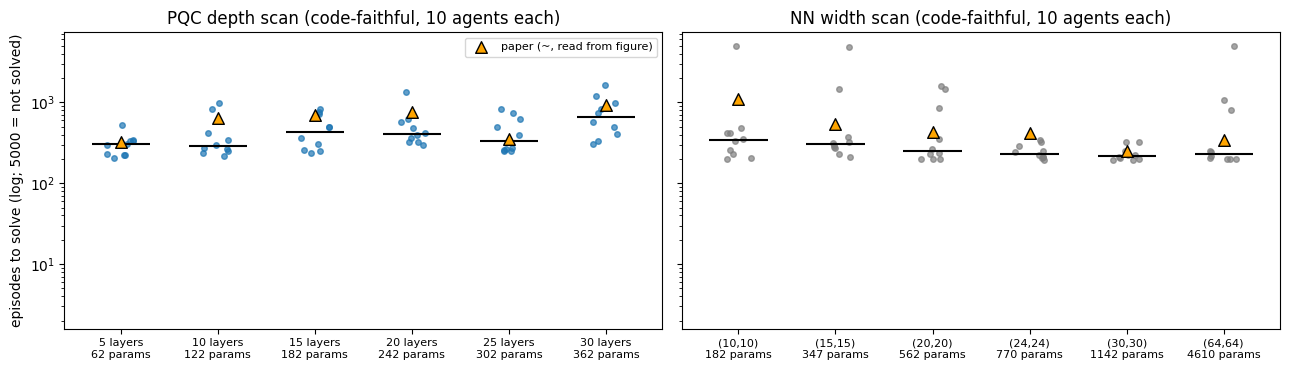

Frozen Lake, paper Fig. 3 (code-faithful)


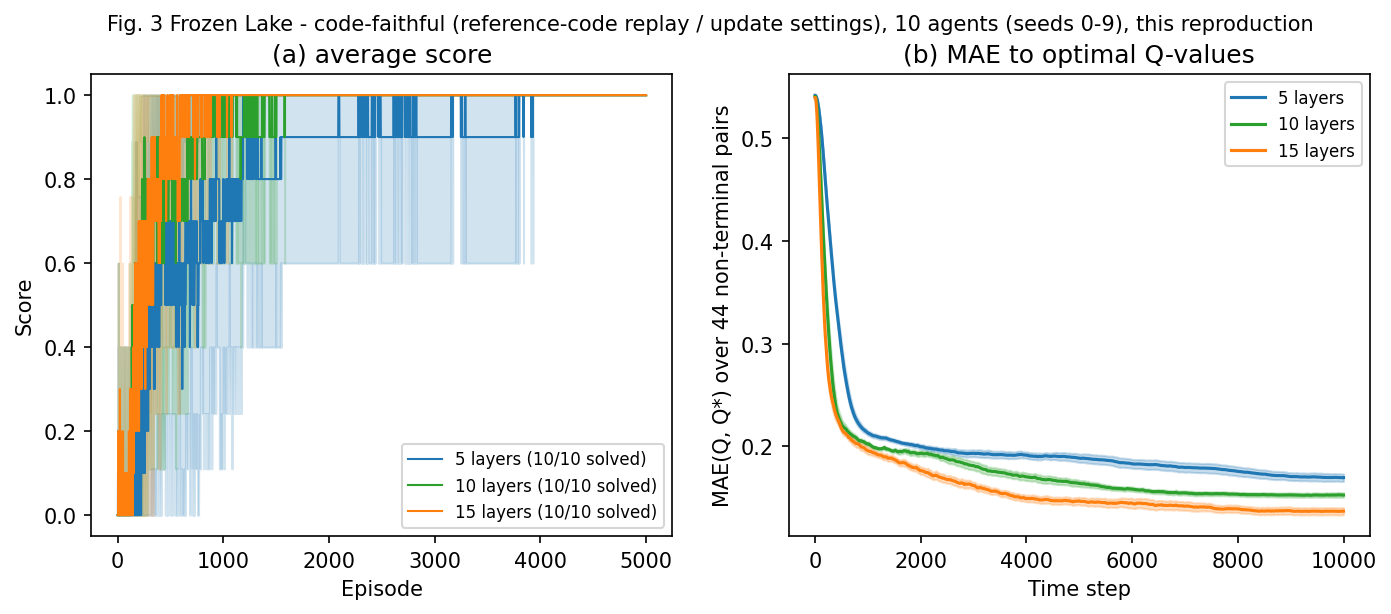

Cart Pole encoding ablation, paper Fig. 4 (code-faithful)


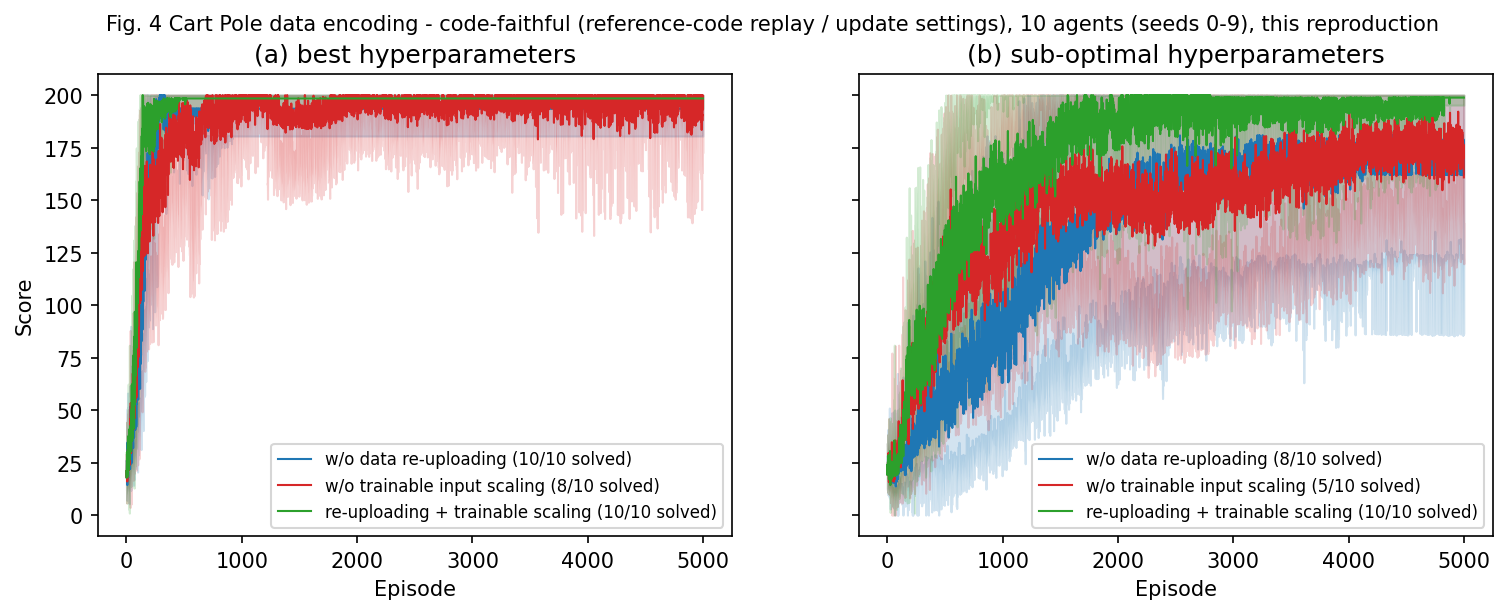

In [9]:
# stored: individual agents (dots), median (bar) and the paper's value (triangle) for the PQC depth scan and NN width scan (Fig. 6).
PAPER_6A = {5: 320, 10: 635, 15: 690, 20: 770, 25: 350, 30: 940}
PAPER_6B = {"10_10": 1110, "15_15": 540, "20_20": 430, "24_24": 415, "30_30": 250, "64_64": 345}
rng = np.random.default_rng(0)
def strip(ax, items, colour, paper=None, labels=None):
    for i, vals in enumerate(items):
        vals = censored(vals)
        ax.scatter(i + rng.uniform(-.15, .15, len(vals)), vals, s=16, color=colour, alpha=.7, zorder=3)
        ax.hlines(np.median(vals), i - .3, i + .3, color="k", zorder=4)
    if paper is not None:
        ax.scatter(range(len(items)), paper, marker="^", color="orange", edgecolor="k", s=70, zorder=5, label="paper (~, read from figure)")
    ax.set_yscale("log"); ax.set_xticks(range(len(items))); ax.set_xticklabels(labels, fontsize=8)

pqc_stems = {d: ("e2e3_cartpole_optimal_full_original" if d == 5 else f"e4_cartpole_pqc_l{d}_original") for d in PAPER_6A}
nn_stems = {w: f"e4_cartpole_mlp_{w}_classical" for w in PAPER_6B}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
strip(axes[0], [stats_cf[pqc_stems[d]]["solved_episode_indices"] for d in PAPER_6A], "tab:blue", list(PAPER_6A.values()),
      [f"{d} layers\n{stats_cf[pqc_stems[d]]['trainable_parameters']} params" for d in PAPER_6A])
strip(axes[1], [stats_cf[nn_stems[w]]["solved_episode_indices"] for w in PAPER_6B], "tab:gray", list(PAPER_6B.values()),
      [f"({w.replace('_', ',')})\n{stats_cf[nn_stems[w]]['trainable_parameters']} params" for w in PAPER_6B])
axes[0].set(ylabel="episodes to solve (log; 5000 = not solved)", title="PQC depth scan (code-faithful, 10 agents each)")
axes[1].set(title="NN width scan (code-faithful, 10 agents each)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

for caption, file in [("Frozen Lake, paper Fig. 3 (code-faithful)", "fig3_frozenlake_codefaithful.png"), ("Cart Pole encoding ablation, paper Fig. 4 (code-faithful)", "fig4_encoding_ablation_codefaithful.png")]:
    print(caption); display(Image(filename=str(RES / "figures" / file), width=760))

**Observation.** (i) The 5-layer PQC solves Cart Pole in 303 episodes on average (10/10 agents), the paper's figure shows about 320; the best individual agents (208 PQC, 191 NN) match the paper's 206 and 186. (ii) All 30 Frozen Lake agents solve at 5, 10 and 15 layers, faster with depth (1323, 821, 749 episodes), and the error to Q* ends at 0.169, 0.152, 0.137, ordered by depth but about 0.02 below the paper's curves. (iii) Fixed output range [0,1] never solves. (iv) Not reproduced: Cart Pole **without re-uploading** (10/10 solve with the best settings) and **without trainable input scaling** (8/10) still solve, and fixed range [0,180] with the sub-optimal settings solves 9/10, where the paper says these fail. (v) Several depths of Fig. 6a (10, 15, 20 layers) solve faster than the paper's dashed lines.
**Inference.** The central positive results (C4, C6, the Frozen Lake picture of C1, the output-range part of C2) reproduce with the authors' released settings. The paper's *absolute* "does not solve" statements do not; the ablated models are slower and less reliable (section 9) but not unable.
**Remaining uncertainty.** The paper's Fig. 6 values are read by eye; its text and figure disagree on the best average PQC and NN; its own Fig. 4a curves for the ablated arms sit near 190, so the text may be stricter than its data.
**Claim impact.** C4, C6 reproduced; C1, C2, C3, C5 partially reproduced.

## 8. Fair baseline comparison (stored, with live statistics)

**The comparative claim (C5):** "the best NN solves Cart Pole in about half as many episodes as the best PQC, with about twice the parameters". The paper's own NN arms are *not* matched to its circuits on parameter count (its smallest NN has 182 parameters; its 5-layer PQC has 62) and the tuning budget of either family is unreported. We therefore added NNs of matching size and gave all four models the **same tuning grid**, then evaluated the selected settings on fresh seeds.

**What is matched and what is not**

| Dimension | PQC vs NN comparison here |
|---|---|
| Information and inputs | matched: the same 4 raw observations, same environment and episode cap |
| Parameter count | matched within 8%: 62 vs 67 and 302 vs 310 (the NN has two hidden layers of 5 and 14 units) |
| Training data | matched: the same online interaction budget (cap 5000 episodes), replay unbounded for both |
| Optimisation steps | matched rule (update every step for the 5-layer PQC and the NNs, every 10 for the 25-layer PQC as in the paper); the *number* of steps differs because agents stop when solved |
| Tuning budget | matched: the same 6-setting grid (batch {16, 32, 64} x target update {1, 30}) on separate selection seeds 100-104, selection by median episodes to solve (5% tie rule) |
| Compute and wall time | **not matched**: NNs ran on a laptop CPU (53-199 s), circuits on a remote GPU (1947-6770 s); reported, never used for a claim |
| Evaluation protocol | matched: seeds 0-9, same solve rule, same censoring |

The paper's own NN widths, untuned matched NNs and a photonic model are shown for context; they are not parameter-matched or tuned like the main pairs.

,system,role,params,solved,median [95% CI],mean,wall-clock s,hardware
0,"PQC 5 layers, tuned",paper method,62,10/10,"214 [195, 266]",262,1947,remote L4
1,"NN (5,5), tuned",added fair baseline,67,10/10,"298 [252, 1520]",964,199,laptop CPU
2,"PQC 25 layers, tuned (= paper setting)",paper method,302,10/10,"332 [254, 616]",435,6770,remote L4
3,"NN (14,14), tuned",added fair baseline,310,10/10,"232 [214, 297]",304,53,laptop CPU
4,"PQC 5 layers, paper setting",paper method (context),62,10/10,"303 [224, 337]",303,2759,remote L4
5,"NN (5,5), untuned",baseline before tuning (context),67,5/10,"4910 [622, 5000]",3236,263,laptop CPU
6,"NN (14,14), untuned",baseline before tuning (context),310,10/10,"387 [240, 2164]",1168,198,laptop CPU
7,"NN (20,20), paper setting",paper baseline (context),562,10/10,"250 [199, 900]",556,110,laptop CPU
8,"NN (30,30), paper setting",paper baseline (context),1142,10/10,"216 [199, 272]",234,29,laptop CPU
9,MerLin 5 layers (adaptation),photonic adaptation,82,10/10,"280 [203, 400]",304,6028,remote CPU


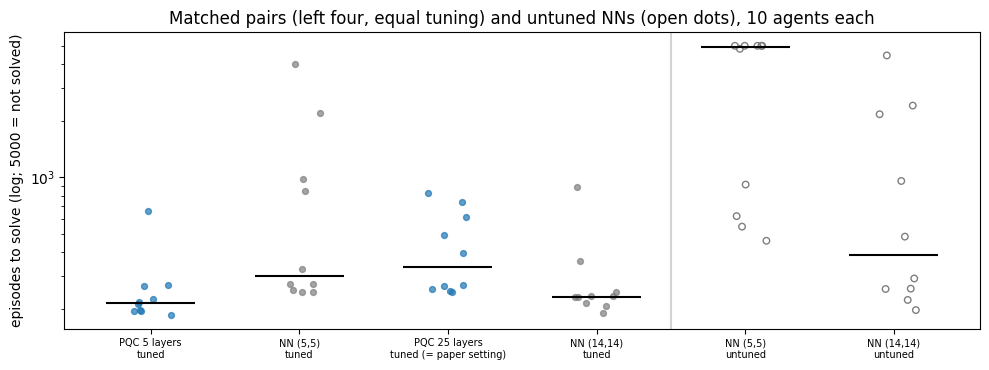

PQC 5 layers, tuned  vs  NN (5,5), tuned
   medians 214 vs 298; difference -84 [95% CI -1306, -16]; Mann-Whitney p = 0.0046 (stored table: 0.0046)
PQC 25 layers, tuned (= paper setting)  vs  NN (14,14), tuned
   medians 332 vs 232; difference +100 [95% CI 17, 384]; Mann-Whitney p = 0.0091 (stored table: 0.0091)


In [10]:
# stored: the matched comparison (results/phase5_comparison.json, generated by utils/compare_phase5.py)
rows = phase5["rows"]
table = pd.DataFrame([{"system": k, "role": v["role"], "params": v["trainable_parameters"], "solved": f"{v['solved']}/10",
                       "median [95% CI]": f"{v['median_censored']:.0f} [{v['median_ci95'][0]:.0f}, {v['median_ci95'][1]:.0f}]",
                       "mean": round(v["mean_censored"]), "wall-clock s": round(v["wall_clock_seconds"]), "hardware": v["hardware"]} for k, v in rows.items()])
display(table)

groups = ["PQC 5 layers, tuned", "NN (5,5), tuned", "PQC 25 layers, tuned (= paper setting)", "NN (14,14), tuned"]
untuned = ["NN (5,5), untuned", "NN (14,14), untuned"]
per_agent = {k: solved_at[rows[k]["config"]]["solved_at"] for k in groups + untuned}
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, k in enumerate(groups + untuned):
    vals = censored(per_agent[k]); colour = "tab:blue" if "PQC" in k else "tab:gray"
    if "untuned" in k:
        ax.scatter(i + rng.uniform(-.15, .15, 10), vals, s=22, facecolors="none", edgecolors=colour, zorder=3)
    else:
        ax.scatter(i + rng.uniform(-.15, .15, 10), vals, s=18, color=colour, alpha=.7, zorder=3)
    ax.hlines(np.median(vals), i - .3, i + .3, color="k", zorder=4)
ax.axvline(3.5, color="lightgray"); ax.set_yscale("log")
ax.set_xticks(range(6)); ax.set_xticklabels([k.replace(", ", "\n") for k in groups + untuned], fontsize=7)
ax.set(ylabel="episodes to solve (log; 5000 = not solved)", title="Matched pairs (left four, equal tuning) and untuned NNs (open dots), 10 agents each")
plt.tight_layout(); plt.show()

# live statistics from the per-agent values: Mann-Whitney U (two-sided) and a bootstrap interval of the median difference.
rng_b = np.random.default_rng(1)
def compare(a_name, b_name):
    a, b = censored(per_agent[a_name]), censored(per_agent[b_name])
    p = stats.mannwhitneyu(a, b, alternative="two-sided").pvalue
    diff = np.median(rng_b.choice(a, (10000, 10)), 1) - np.median(rng_b.choice(b, (10000, 10)), 1)
    return np.median(a), np.median(b), p, np.percentile(diff, [2.5, 97.5])
for a_name, b_name in [(groups[0], groups[1]), (groups[2], groups[3])]:
    ma, mb, p, ci = compare(a_name, b_name)
    stored_p = [pair["mann_whitney_p"] for pair in phase5["pairs"] if pair["a"] == a_name and pair["b"] == b_name][0]
    print(f"{a_name}  vs  {b_name}\n   medians {ma:.0f} vs {mb:.0f}; difference {ma-mb:+.0f} [95% CI {ci[0]:.0f}, {ci[1]:.0f}]; Mann-Whitney p = {p:.4f} (stored table: {stored_p:.4f})")
    assert abs(p - stored_p) < 1e-9

**Observation.** At about 65 parameters the tuned PQC solves faster than the tuned NN (median 214 vs 298 episodes, p = 0.005; the NN has two slow agents). At about 300 parameters the order reverses: the tuned NN is faster (232 vs 332, p = 0.009). Tuning changed the small NN from 5/10 solved to 10/10 (open dots versus filled). The live statistics reproduce the stored p-values exactly.
**Inference.** Neither model family is better in general at matched size; the paper's "NN about twice as fast" holds at the larger size and reverses at the smaller one, so that comparison depended on unmatched sizes and unequal (unreported) tuning. Sample efficiency here is dominated by hyperparameters as much as by the model family.
**Remaining uncertainty.** One task, two size pairs, 10 agents, and a selection step on only 5 agents per candidate (section 10); the PQC runs are classical simulation; wall-clock is not comparable across the hardware used.
**Claim impact.** C5 partially supported (non-monotonic trend reproduced; the factor-two statement is size dependent); C6 supported (descriptive). **No quantum advantage is claimed or supported.**

## 9. Controls and ablations

Each control changes **one** thing, to test an explanation of a discrepancy or of the paper's mechanism.

In [11]:
# 9a (stored) Why do the paper's tables and the paper's figures disagree? Single-change controls on the released-code settings.
def summarise(stem, source):
    r = source[stem]; return f"{r['solved']}/{r['agents']} solved, mean {r['mean_censored']:.0f} [{r['mean_censored_ci95'][0]:.0f}, {r['mean_censored_ci95'][1]:.0f}]"
rows = [("Cart Pole 5-layer PQC, paper table (replay 10000)", summarise("e2e3_cartpole_optimal_full_original", stats_pt)),
        ("   control: unbounded replay only (released code)", summarise("e2_cartpole_optimal_full_unbounded_replay_variant", stats_pt)),
        ("   paper figure (Fig. 6a, read by eye)", "~320"),
        ("Frozen Lake 5 layers, paper table (update every 5 steps)", summarise("e1_frozenlake_l5_original", stats_pt)),
        ("   control: update every step only (released code)", summarise("e1_frozenlake_l5_updateevery1_variant", stats_pt)),
        ("Frozen Lake, ring ansatz of Fig. 1 instead of the code's ansatz", summarise("e1_frozenlake_l5_ringansatz_variant", stats_pt)),
        ("Cart Pole, tanh encoding of the code instead of arctan", summarise("e2_cartpole_optimal_full_tanh_variant", stats_pt))]
display(pd.DataFrame(rows, columns=["setting (control)", "result (10 agents, seeds 0-9)"]))

fit = json.loads((RES / "verification" / "frozenlake_qstar_fit.json").read_text())["rows"]
print("Known-answer control (supervised fit of Q*, no RL; stored): error after fit / best action matched")
for label in ["qubit code ansatz, 5 layers"]:
    print(f"   {label}: MAE {np.mean(fit[label]['mae44']):.3f}, argmax agreement {np.mean(fit[label]['argmax_agreement']):.2f}")

,setting (control),"result (10 agents, seeds 0-9)"
0,"Cart Pole 5-layer PQC, paper table (replay 10000)","10/10 solved, mean 617 [415, 866]"
1,control: unbounded replay only (released code),"10/10 solved, mean 303 [253, 362]"
2,"paper figure (Fig. 6a, read by eye)",~320
3,"Frozen Lake 5 layers, paper table (update ever...","9/10 solved, mean 2297 [1447, 3170]"
4,control: update every step only (released c...,"10/10 solved, mean 1323 [857, 2016]"
5,"Frozen Lake, ring ansatz of Fig. 1 instead of ...","4/10 solved, mean 4472 [3924, 4988]"
6,"Cart Pole, tanh encoding of the code instead o...","10/10 solved, mean 639 [394, 1029]"


Known-answer control (supervised fit of Q*, no RL; stored): error after fit / best action matched
   qubit code ansatz, 5 layers: MAE 0.105, argmax agreement 0.64


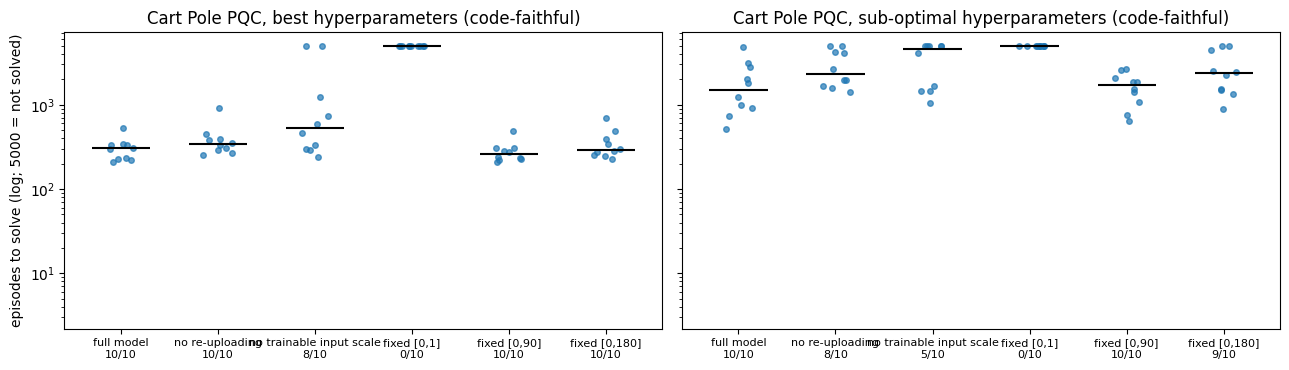

Control: does the code's tanh encoding (instead of arctan) turn the ablated arms into failures?


,hyperparameters,arm,solved (arctan),solved (tanh),mean (arctan),mean (tanh)
0,optimal,full model,10/10,10/10,303,346
1,optimal,no re-uploading,10/10,10/10,394,404
2,optimal,no trainable input scale,8/10,8/10,1420,1417
3,optimal,"fixed [0,180]",10/10,10/10,350,363
4,suboptimal,full model,10/10,9/10,1901,1935
5,suboptimal,no re-uploading,8/10,6/10,2961,3460
6,suboptimal,no trainable input scale,5/10,4/10,3472,3814
7,suboptimal,"fixed [0,180]",9/10,8/10,2686,2933


In [12]:
# 9b (stored) Encoding and readout ablations, both hyperparameter sets (code-faithful set; Fig. 4 and Fig. 5 of the paper).
arms = [("full", "full model"), ("no_reuploading", "no re-uploading"), ("no_input_weights", "no trainable input scale"),
        ("fixed_range_1", "fixed [0,1]"), ("fixed_range_90", "fixed [0,90]"), ("fixed_range_180", "fixed [0,180]")]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, setting, title in [(axes[0], "optimal", "best hyperparameters"), (axes[1], "suboptimal", "sub-optimal hyperparameters")]:
    strip(ax, [stats_cf[f"e2e3_cartpole_{setting}_{a}_original"]["solved_episode_indices"] for a, _ in arms], "tab:blue",
          labels=[f"{label}\n{stats_cf[f'e2e3_cartpole_{setting}_{a}_original']['solved']}/10" for a, label in arms])
    ax.set_title(f"Cart Pole PQC, {title} (code-faithful)")
axes[0].set_ylabel("episodes to solve (log; 5000 = not solved)"); plt.tight_layout(); plt.show()

diag = {k: solved_at[k]["solved_at"] for k in solved_at if k.endswith("tanh_diagnostic")}
rows = []
for setting in ("optimal", "suboptimal"):
    for a, label in arms[:3] + arms[5:]:
        arc = stats_cf[f"e2e3_cartpole_{setting}_{a}_original"]; tanh = diag[f"e2e3_cartpole_{setting}_{a}_codefaithful_tanh_diagnostic"]
        rows.append((setting, label, f"{arc['solved']}/10", f"{sum(v is not None for v in tanh)}/10", round(arc['mean_censored']), round(censored(tanh).mean())))
print("Control: does the code's tanh encoding (instead of arctan) turn the ablated arms into failures?")
display(pd.DataFrame(rows, columns=["hyperparameters", "arm", "solved (arctan)", "solved (tanh)", "mean (arctan)", "mean (tanh)"]))

**Observation.** (i) With the paper's tables the 5-layer Cart Pole model needs 617 episodes; changing *only* the replay memory to the released code's unbounded one gives 303, the value in the paper's figure. Changing *only* the Frozen Lake update frequency to every step makes all agents solve and the error to Q* fall as fast as in Fig. 3b. (ii) The ring ansatz drawn in Fig. 1 solves Frozen Lake in only 4 of 10 agents; the code's ansatz in 10 of 10. (iii) The `tanh` encoding does not turn any ablated arm into a failure (0-2 agents fewer or more solved out of 10, means within about 17%). (iv) The ablations slow learning and make it less reliable, most clearly with the sub-optimal hyperparameters, but do not stop it; fixed [0,1] fails everywhere.
**Inference.** The two released-code settings, not a bug in our simulator, explain most of the gap between the paper's *tables* and its *figures*; the ring-ansatz failure is a property of the circuit (its last RZ and CZ layers commute with a Z readout). Re-uploading and trainable input scaling help (C3 in direction) but are not strictly necessary on this task in our runs; the output range *is* decisive in the extreme case (C2).
**Remaining uncertainty.** Why the paper reports complete failure for the ablated arms and for fixed [0,180] with sub-optimal settings is unexplained: implementation and settings match the released code, and tanh does not explain it. Selection leakage caveat: the decision to use the released code's two settings as the comparison set was taken after the paper-table runs on seeds 0-9 had been compared with the paper's figures. The settings themselves come from the authors' code, not from a search over our results, and each was tested as a single-change control, but the agreement of the code-faithful set with the paper is therefore not an independent confirmation.
**Claim impact.** C2 and C3 partially supported (directions reproduced, absolute failure statements not); C1 supported with the released code's circuit.

## 10. Robustness and uncertainty

How stable are the conclusions under seeds, tuning choices, statistics and hardware?

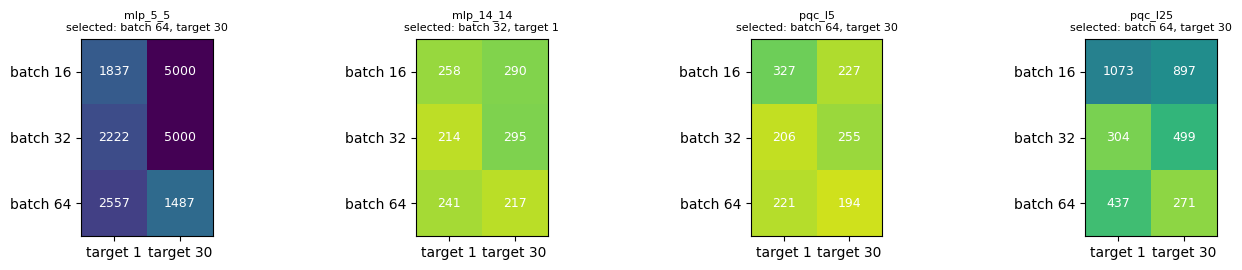

sweep completeness: 24 of 24 planned candidates observed (4 models x 6 settings); ties within 5%: {'mlp_14_14': ['e5_select_mlp_14_14_b64_t30_classical']}


In [13]:
# 10a (stored) Tuning-grid sweep: median episodes to solve of all 24 candidates (5 selection agents each, seeds 100-104).
sel = {**json.loads((RES / "phase5_selection_nn.json").read_text())["models"], **json.loads((RES / "phase5_selection_pqc.json").read_text())["models"]}
fig, axes = plt.subplots(1, 4, figsize=(14, 2.8))
for ax, (model, info) in zip(axes, sel.items()):
    grid = np.array([[next(c for c in info["candidates"] if c["batch_size"] == b and c["update_target_every"] == t)["median_censored"] for t in (1, 30)] for b in (16, 32, 64)])
    image = ax.imshow(np.log10(grid), cmap="viridis_r", vmin=np.log10(150), vmax=np.log10(5000))
    for i in range(3):
        for j in range(2): ax.text(j, i, f"{grid[i, j]:.0f}", ha="center", va="center", color="w", fontsize=9)
    best = info["selected_batch_size"], info["selected_update_target_every"]
    ax.set_title(f"{model}\nselected: batch {best[0]}, target {best[1]}", fontsize=8)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["target 1", "target 30"]); ax.set_yticks(range(3)); ax.set_yticklabels(["batch 16", "batch 32", "batch 64"])
plt.tight_layout(); plt.show()
print("sweep completeness: 24 of 24 planned candidates observed (4 models x 6 settings); ties within 5%:",
      {m: [c for c in i["tied_candidates"] if c != i["selected"]] for m, i in sel.items() if len(i["tied_candidates"]) > 1})

In [14]:
# 10b Sensitivity of the matched-pair conclusion: statistic (median vs mean), baseline tuning, and a bootstrap probability.
def prob_faster(a_name, b_name, statistic=np.median, draws=20000, seed=2):
    g = np.random.default_rng(seed); a, b = censored(per_agent[a_name]), censored(per_agent[b_name])
    return float(np.mean(statistic(g.choice(a, (draws, 10)), 1) < statistic(g.choice(b, (draws, 10)), 1)))
rows = []
for a_name, b_name in [(groups[0], groups[1]), (groups[0], untuned[0]), (groups[2], groups[3]), (groups[2], untuned[1])]:
    a, b = censored(per_agent[a_name]), censored(per_agent[b_name])
    rows.append((f"{a_name.split(',')[0]} vs {b_name}", f"{np.median(a):.0f} vs {np.median(b):.0f}", f"{a.mean():.0f} vs {b.mean():.0f}",
                 f"{stats.mannwhitneyu(a, b).pvalue:.3f}", f"{prob_faster(a_name, b_name):.2f}", f"{prob_faster(a_name, b_name, np.mean):.2f}"))
display(pd.DataFrame(rows, columns=["pair (A vs B)", "medians", "means", "Mann-Whitney p", "P(A median < B median), bootstrap", "P(A mean < B mean), bootstrap"]))
print("seeds per comparison: 10 (0-9); selection seeds 100-104 are disjoint from evaluation seeds.")

,pair (A vs B),medians,means,Mann-Whitney p,"P(A median < B median), bootstrap","P(A mean < B mean), bootstrap"
0,"PQC 5 layers vs NN (5,5), tuned",214 vs 298,262 vs 964,0.005,0.99,1.00
1,"PQC 5 layers vs NN (5,5), untuned",214 vs 4910,262 vs 3236,0.000,1.00,1.00
2,"PQC 25 layers vs NN (14,14), tuned",332 vs 232,435 vs 304,0.009,0.01,0.08
3,"PQC 25 layers vs NN (14,14), untuned",332 vs 387,435 vs 1168,0.623,0.62,0.97


seeds per comparison: 10 (0-9); selection seeds 100-104 are disjoint from evaluation seeds.


**Observation.** The tuning grid is flat for the 5-layer PQC and for NN (14,14) (all six settings within a factor 1.7 of the best), worse at batch 16 for the 25-layer PQC (about 900-1100 vs 270-500 episodes), and sharply sensitive for the small NN (target update 30 fails except with batch 64). For the tuned pairs the direction is the same under the median and the mean (bootstrap probabilities 0.99 and 1.00 at ~65 parameters, 0.01 and 0.08 at ~300). Against the *untuned* NNs the picture changes: at ~65 parameters the PQC's lead is large (median 214 vs 4910, the untuned NN solves 5/10; an untuned baseline is not a fair comparison), and at ~300 parameters the medians are not distinguishable (332 vs 387, p = 0.62) while the PQC mean is lower (435 vs 1168), whereas against the tuned NN the PQC is slower. Intervals over 10 agents are wide (a median's interval spans a factor from 1.4 for the 5-layer PQC to 6 for NN (5,5)).
**Inference.** The sign of the comparison at ~300 parameters, and the size of the PQC's lead at ~65, depend on how well the baseline is tuned: reporting only an untuned or unmatched baseline would have produced a much stronger-looking PQC result. The matched, equally tuned comparison is the defensible one.
**Remaining uncertainty.** Selection used 5 agents per candidate; a different seed set could select other settings (two NN candidates tied within 5% in one case). Seed-level results do not transfer across devices (section 6b), so exact numbers are specific to the hardware used; conclusions are drawn on distributions.
**Claim impact.** C5 stays partially supported; no new claim.

## 11. Photonic adaptation with MerLin (extension, not part of the reproduction)

**Question.** Does the paper's recipe (a bounded per-action output with matched range, data re-uploading with trainable input scaling, standard DQN) carry over to **linear optics**, and what changes?

**Mapping (`lib/qfunction_merlin.py`).** 6 modes, 3 photons, input state $|1,0,1,0,1,0\rangle$. Each layer is a brickwork of Mach-Zehnder interferometers on neighbouring modes (10 phases); the state enters as phase shifters on modes 0-3 (Cart Pole $\arctan(x_i w_i)$, re-uploaded every layer; Frozen Lake $\pi\cdot$bit, once as in the paper). $Q(s,a)$ = click probability of a **threshold detector** on a readout mode (times $w_o$), bounded in [0,1] like $(\langle Z\rangle+1)/2$. The full Fock space is simulated and each outcome collapsed to click / no-click, so there is **no post-selection** (MerLin's `UNBUNCHED` space would post-select on 3-click events, checked below). Settings otherwise identical to the code-faithful qubit runs; the photonic model is untuned, with 82 parameters instead of 62. All results are simulations with ideal components.

In [15]:
# 11a (live) Known-answer checks of the photonic building blocks.
# (i) Hong-Ou-Mandel: two photons on a 50:50 beam splitter bunch; P(1,1) = 0.
backend = perceval.SLOSBackend(); backend.set_circuit(perceval.Circuit(2) // perceval.BS()); backend.set_input_state(perceval.BasicState([1, 1]))
print("(i) HOM, outcome probabilities:", {str(k): round(float(v), 4) for k, v in backend.prob_distribution().items()})

# (ii) The MerLin model equals an independent Perceval SLOS simulation of the same circuit.
from lib.qfunction_merlin import build_circuit
def perceval_clicks(model, agent, observation):
    circuit, _, _ = build_circuit(model.n_modes, model.n_layers, model.n_inputs, model.data_reuploading)
    mesh = model.theta[agent].detach().double()
    enc = model.encoding_phases(observation.expand(model.n_agents, 1, observation.shape[-1]))[agent, 0].detach().double()
    for parameter in circuit.get_parameters():
        index = int(parameter.name[1:]); parameter.set_value(float((mesh[index] if parameter.name.startswith("w") else enc[index]) % (2 * np.pi)))
    sim = perceval.SLOSBackend(); sim.set_circuit(circuit); sim.set_input_state(perceval.BasicState(model.input_state))
    clicks = torch.zeros(model.n_modes, dtype=torch.float64)
    for state, probability in sim.prob_distribution().items():
        clicks += torch.tensor([float(n > 0) for n in state]) * probability
    return clicks
cfg_m = load_config("e2e3_cartpole_optimal_full_merlin")
model_m = MerlinQFunction(cfg_m, [3, 11], 2, torch.float64)
x = torch.randn(1, 1, 4, dtype=torch.float64, generator=torch.Generator().manual_seed(0))
worst = max(float((model_m.click_probabilities(x.expand(2, 1, 4))[a, 0] - perceval_clicks(model_m, a, x[0, 0])).abs().max()) for a in range(2))
print(f"(ii) max |MerLin click probabilities - Perceval SLOS|: {worst:.1e}")
assert worst < 1e-7

# (iii) MerLin's UNBUNCHED space post-selects: expected clicks always sum to the photon number; threshold detection does not.
cfg_u = load_config("e2e3_cartpole_optimal_full_merlin"); cfg_u["model"]["readout"] = "unbunched_click"
batch = torch.randn(1, 6, 4, dtype=torch.float64)
unbunched = MerlinQFunction(cfg_u, [0], 2, torch.float64).click_probabilities(batch).sum(-1)
threshold = MerlinQFunction(cfg_m, [0], 2, torch.float64).click_probabilities(batch).sum(-1)
print("(iii) sum of expected clicks, UNBUNCHED readout:", [round(float(v), 3) for v in unbunched[0]], "| threshold readout:", [round(float(v), 3) for v in threshold[0]])

(i) HOM, outcome probabilities: {'|0,2>': 0.5, '|2,0>': 0.5}
(ii) max |MerLin click probabilities - Perceval SLOS|: 6.1e-09
(iii) sum of expected clicks, UNBUNCHED readout: [3.0, 3.0, 3.0, 3.0, 3.0, 3.0] | threshold readout: [2.304, 2.385, 2.363, 2.264, 2.427, 2.46]


In [16]:
# 11b (live, ~25 s) Why can the planned photonic Frozen Lake model not learn? Supervised fit of Q* (no RL), as in section 9.
alive = [s for s in range(16) if s not in terminal_states()]
target = torch.tensor(optimal_q_values(0.8), dtype=torch.float64)[alive]
states = torch.tensor(alive, dtype=torch.float64).view(1, -1, 1)
results = {}
for label, make in [("qubit code ansatz, 5 layers", lambda: build_q_function(dfq.load_config("e1_frozenlake_l5_codefaithful"), dfq.SEEDS, 4, torch.float64)),
                    ("photonic, state encoded once (planned)", lambda: MerlinQFunction(dfq.load_config("e1_frozenlake_l5_merlin"), dfq.SEEDS, 4, torch.float64)),
                    ("photonic, state re-uploaded every layer", lambda: MerlinQFunction(dfq.load_config("e1_frozenlake_l5_merlin_reupload"), dfq.SEEDS, 4, torch.float64))]:
    results[label] = dfq.fit(make(), states, target)
display(pd.DataFrame([{"model": k, "MAE to Q* after fit": round(float(np.mean(v["mae44"])), 3), "best action matched (fraction)": round(float(np.mean(v["argmax_agreement"])), 2)} for k, v in results.items()]))

# 11c (live, ~10 s) A short photonic RL run: the model builds, trains and acts (2 agents, 40 episodes). Reduction: not a learning-curve claim.
cfg_run = load_config("e2e3_cartpole_optimal_full_merlin"); cfg_run["agents"]["seeds"] = [0, 1]; cfg_run["training"]["max_episodes"] = 40
start = time.perf_counter(); live_m = DQNTrainer(cfg_run, DEVICE, torch.float32).train()
print(f"photonic smoke run: {time.perf_counter() - start:.0f} s, {live_m.trainable_parameters} trainable parameters per agent, "
      f"mean score of the last 10 episodes {[round(float(np.mean(s[-10:])), 1) for s in live_m.scores]}")

,model,MAE to Q* after fit,best action matched (fraction)
0,"qubit code ansatz, 5 layers",0.105,0.64
1,"photonic, state encoded once (planned)",0.148,0.45
2,"photonic, state re-uploaded every layer",0.061,0.85


photonic smoke run: 8 s, 82 trainable parameters per agent, mean score of the last 10 episodes [43.0, 38.0]


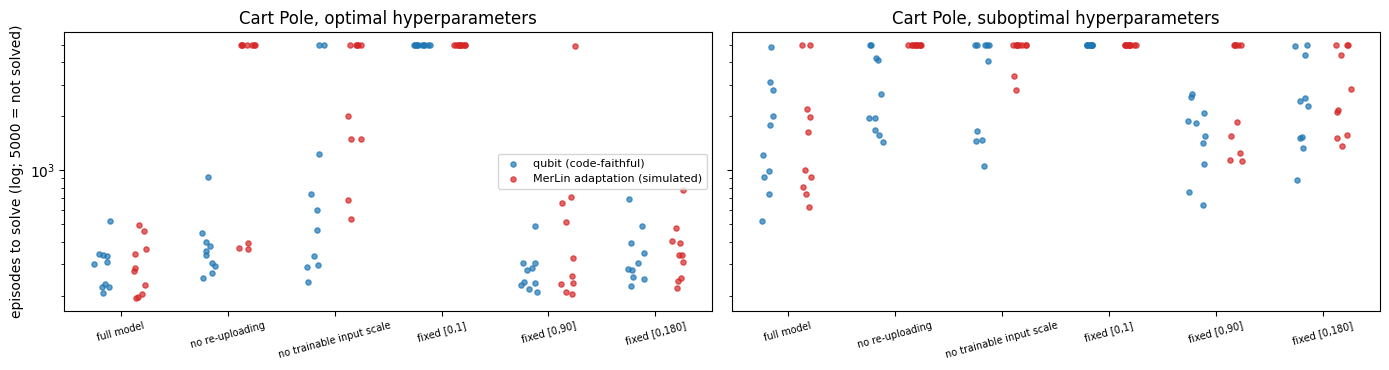

,Frozen Lake config,MerLin solved,MerLin mean,qubit solved,qubit mean,MAE@10k MerLin / qubit
0,e1_frozenlake_l10_merlin,0/10,5000,10/10,821,0.252 / 0.152
1,e1_frozenlake_l10_merlin_dualrail,0/10,5000,10/10,821,0.197 / 0.152
2,e1_frozenlake_l10_merlin_reupload,10/10,501,10/10,821,0.128 / 0.152
3,e1_frozenlake_l15_merlin,0/10,5000,10/10,749,0.254 / 0.137
4,e1_frozenlake_l15_merlin_reupload,10/10,545,10/10,749,0.083 / 0.137
5,e1_frozenlake_l5_merlin,0/10,5000,10/10,1323,0.251 / 0.169
6,e1_frozenlake_l5_merlin_8modes,0/10,5000,10/10,1323,0.372 / 0.169
7,e1_frozenlake_l5_merlin_dualrail,0/10,5000,10/10,1323,0.195 / 0.169
8,e1_frozenlake_l5_merlin_reupload,7/10,2093,10/10,1323,0.205 / 0.169


Design screen (supervised fit of Q*, stored): single-encoding designs vs re-uploading


,design,MAE to Q*,best action matched,params
0,"phase once, 6 modes / 3 photons, 5 layers (pla...",0.148,0.45,60
1,"phase once, 8 modes / 4 photons, 5 layers",0.151,0.48,84
2,"phase once, 8 modes / 4 photons, 10 layers",0.152,0.45,154
3,"phase once, 10 modes / 5 photons, 5 layers",0.152,0.48,108
4,"dual-rail input, 8 modes / 4 photons, 5 layers",0.135,0.70,84
5,"dual-rail input, 8 modes / 4 photons, 10 layers",0.136,0.61,154
6,"phase re-uploaded, 6 modes / 3 photons, 5 laye...",0.061,0.85,60


In [17]:
# 11d (stored) Photonic results vs the code-faithful qubit model: individual agents, 10 per setting (results/merlin_comparison.json).
cp_arms = [(s, a) for s in ("optimal", "suboptimal") for a, _ in arms]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, setting in zip(axes, ("optimal", "suboptimal")):
    for i, (a, label) in enumerate(arms):
        q = censored(solved_at[f"e2e3_cartpole_{setting}_{a}_codefaithful"]["solved_at"]); m = censored(solved_at[f"e2e3_cartpole_{setting}_{a}_merlin"]["solved_at"])
        ax.scatter(i - .18 + rng.uniform(-.08, .08, 10), q, s=14, color="tab:blue", alpha=.7, label="qubit (code-faithful)" if i == 0 else None)
        ax.scatter(i + .18 + rng.uniform(-.08, .08, 10), m, s=14, color="tab:red", alpha=.7, label="MerLin adaptation (simulated)" if i == 0 else None)
    ax.set_yscale("log"); ax.set_xticks(range(len(arms))); ax.set_xticklabels([label for _, label in arms], fontsize=7, rotation=15)
    ax.set_title(f"Cart Pole, {setting} hyperparameters")
axes[0].set_ylabel("episodes to solve (log; 5000 = not solved)"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

rows = []
for name in [n for n in merlin_cmp if "frozenlake" in n]:
    m, q = merlin_cmp[name]["merlin"], merlin_cmp[name]["qubit"]
    rows.append((name, f"{m['solved']}/10", round(m["mean_censored"]), f"{q['solved']}/10", round(q["mean_censored"]), f"{m['mae44_at_10000']:.3f} / {q['mae44_at_10000']:.3f}"))
display(pd.DataFrame(rows, columns=["Frozen Lake config", "MerLin solved", "MerLin mean", "qubit solved", "qubit mean", "MAE@10k MerLin / qubit"]))

screen = json.loads((RES / "verification" / "frozenlake_design_screen.json").read_text())["rows"]
print("Design screen (supervised fit of Q*, stored): single-encoding designs vs re-uploading")
display(pd.DataFrame([{"design": k, "MAE to Q*": round(float(np.mean(v["mae44"])), 3), "best action matched": round(float(np.mean(v["argmax_agreement"])), 2), "params": v["trainable_parameters"]} for k, v in screen.items()]))

**Hardware-aware settings (all MerLin configurations; simulation only):** computation space `FOCK` (simulated) with threshold-occupancy readout; detector model threshold; post-selection none; 3 photons (design study: 4); 6 modes (design study: 8); input state [1,0,1,0,1,0]; phase encoding on modes 0-3 as above; measurement click probability per readout mode; simulator MerLin 0.4.2 analytic (exact probabilities, no shots), exact gradients; ideal lossless components; seeds 0-9; wall-clock per Cart Pole configuration 3296-44289 s on the remote CPU (8 runs in parallel; per-run values in `results/merlin_comparison.json`).

**Observation.** (i) The photonic Cart Pole model with re-uploading solves 10/10 agents in 304 episodes, indistinguishable from the qubit model (303), and fixed output range [0,1] fails as in the paper. (ii) Without re-uploading or without trainable input scaling the photonic agents are much worse than the qubit ones (3/10 and 5/10 solved with the best settings), closer to the paper's statement. (iii) Frozen Lake with the state encoded once (the paper's design) never solves (0/10 at every depth); in the supervised test the error stays near 0.15 and the best action is matched on about 45% of states. Re-uploading the state before every layer fixes both (7/10, 10/10, 10/10 solved; error to Q* 0.205, 0.128, 0.083). (iv) More modes and photons, more layers and a dual-rail input-state encoding do not fix it (design screen above; 8-mode and dual-rail agents solved 0/10).
**Inference.** After a single phase encoding, everything in the circuit is one fixed linear-optical transformation, whose parameters cannot shape the click probabilities of 16 encoded states freely; repeating the encoding is what gives the model its flexibility, mirroring the role of re-uploading in the paper. The MerLin `UNBUNCHED` space post-selects, so using it would have changed the physics (iii above).
**Remaining uncertainty.** Photonic runs are untuned, have more parameters than the qubit model, and ignore loss and noise; designs outside the examined family (photon-number-resolving readout, adaptive measurements, nonlinear elements) were not tested; the depth scan (E4) was not run photonically.
**Claim impact (extension only).** The photonic adaptation preserves the Cart Pole claims (C2, C3 more strongly than the qubit model, C4) but not Frozen Lake with a single encoding (C1). It makes no claim about hardware or advantage.

## 12. Limitations and conclusion

### Limitations (what the evidence does not cover)

- **Reduced or partial pieces.** Live cells use 3 of 10 agents and shortened horizons (6a, 6b, 11c); everything decisive is from stored full runs. The MerLin adaptation covers E1-E3 only (no depth scan), is untuned, and is simulation with ideal components.
- **Substitute environment.** Gymnasium 1.4.0 instead of gym 0.17.2 (equal dynamics by source comparison; different random streams and float32 observations); the authors' TensorFlow stack could not be run, so seeds cannot be matched.
- **Two settings from the released code replace the paper's tables** in the comparison set (code-faithful); the paper-table set is reported alongside. That choice was made after the paper-table results on seeds 0-9 were seen (selection-leakage caveat, section 9), so the code-faithful agreement is supporting, not independent, evidence.
- **Paper reference values** for Figs. 3b and 6 are read by eye (about ±20 episodes); the paper's text and Fig. 6 disagree on the best average circuit and network.
- **Sweeps.** The only selection sweep is the added 24-candidate tuning grid (complete); each candidate has 5 agents. The depth and width scans are descriptive.
- **Missing or unexecuted.** Fig. 8 (Q-value surface) and the Sec. 3.2 toy were not run; the paper's own hyperparameter search is not reproduced; no photonic hardware or noise study.
- **Hardware.** Circuits ran on an L4 GPU, NNs on a laptop CPU, MerLin on a remote CPU; wall-clock is reported but never compared.
- **Qualitative only.** The ablation statements and the PQC-versus-NN order at matched size rest on 10 agents and are supported qualitatively.

### The five outcomes, kept apart

| Outcome | Status | Evidence |
|---|---|---|
| The software executes | yes | sections 4, 6; 79 tests; all batches validated |
| The method solves the task | yes (Cart Pole 10/10, Frozen Lake 30/30 agents with the released code's settings) | sections 6, 7 |
| The paper's metric reproduces | partly: Cart Pole 303 vs ~320; best agents 208/191 vs 206/186; Frozen Lake error ordering yes, level ~0.02 lower; several Fig. 6 depths faster | section 7 |
| The paper's explanation survives controls | partly: output range yes; re-uploading and input scaling help but are not necessary; two table settings explain the table/figure gap | section 9 |
| The method beats a fair baseline | no general winner: PQC faster at ~65 parameters, NN faster at ~300 | section 8 |

### Required conclusion

1. **What reproduced.** The 5-layer PQC solves Cart Pole (303 episodes, 10/10; §7); all Frozen Lake agents solve with depth ordering (§7); fixed output range [0,1] never solves (§7, §9); the best individual agents match (§7); the table-versus-figure gap is explained by two released-code settings (§9).
2. **What did not reproduce.** "Does not solve" for Cart Pole without re-uploading or without trainable input scaling (8/10 to 10/10 still solve); complete failure of fixed [0,180] with sub-optimal hyperparameters (9/10 solve); the Frozen Lake error curve level (0.02 lower) and depth gap (0.033 vs ~0.05); several faster-than-paper Fig. 6a depths (§7, §9).
3. **What remains unresolved.** Why the paper reports those failures (not the `tanh` encoding, §9); whether the TensorFlow code would give our numbers; how seed-level results behave across devices (§6b); whether photonic designs outside the examined family can solve Frozen Lake without re-uploading (§11).
4. **What was not attempted.** Fig. 8 and the Sec. 3.2 toy; the paper's hyperparameter search; the photonic depth scan; photonic hardware, loss or noise; other environments.
5. **Reproduction verdict.** **Partially reproduced** (reproduction quality high, metric agreement moderate, trend agreement good): the central Cart Pole and Frozen Lake results hold with the authors' released settings; several of the paper's absolute statements do not; at matched size the paper's PQC-versus-NN statement is size dependent (§7, §8, §9).
6. **Extension or photonic verdict.** A MerLin adaptation (simulated) preserves the Cart Pole claims and matches the qubit model's speed, but Frozen Lake needs the state re-uploaded in every layer; no quantum or photonic advantage is supported (§8, §11).